# When should the fingerprint matcher say “unknown”?

We freeze the accuracy-first LSH settings from the medium study and calibrate each search method to at most 1% empirical false acceptance on development queries. The test uses different tracks. This notebook reproduces the analysis from the saved GPU scores. See [reproduction instructions](../reports/unknown-songs.md) for audio generation and CUDA search.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "reports/unknown-song-scores.csv.gz").exists())
table = pd.read_csv(root / "reports/unknown-song-scores.csv.gz", dtype={"exact_score":"float32", "lsh_score":"float32"})
assert len(table) == 4096 and table.track_id.nunique() == 2048
assert (table.groupby("track_id").size() == 2).all()
assert (table.groupby("track_id")[["known","phase"]].nunique() == 1).all().all()
assert not table.duplicated(["track_id","family"]).any()
development = table[table.phase == "development"]
test = table[table.phase == "test"]
assert set(development.track_id).isdisjoint(test.track_id)
display(table.groupby(["phase","known"]).track_id.agg(queries="size", tracks="nunique"))

queries  tracks
phase       known                 
development False     1024     512
            True      1024     512
test        False     1024     512
            True      1024     512

## Choose thresholds on development tracks

An identification is accepted when the maximum cosine score reaches the threshold. Ties at the first excluded score are rejected together. The target is an empirical development constraint. We evaluate both error rates afresh on the test set.

In [2]:
target = 0.01
def cutoff(absent_scores):
    scores = np.sort(absent_scores)[::-1]
    return float(np.nextafter(scores[int(np.floor(target * len(scores)))], np.float32(np.inf)))

cutoffs = {m: float(cutoff(development.loc[~development.known, m + "_score"])) for m in ("exact","lsh")}
for method, threshold in cutoffs.items():
    assert (development.loc[~development.known, method + "_score"] >= threshold).mean() <= target
print(cutoffs)

{'exact': 0.8370281457901001, 'lsh': 0.8370278477668762}


## Performance on previously unused tracks

Intervals use 5,000 percentile bootstrap samples of whole tracks within each known/unknown group; the two distortions of a song remain together. Intervals condition on the frozen catalogue and calibrated cutoff.

In [3]:
def rate_interval(values, track_ids):
    means = pd.Series(np.asarray(values, dtype=float)).groupby(np.asarray(track_ids)).mean().to_numpy()
    rng = np.random.default_rng(422)
    samples = rng.choice(means, size=(5000,len(means))).mean(axis=1)
    return [float(means.mean()), *map(float,np.quantile(samples,[.025,.975]))]

rows = []
for method, threshold in cutoffs.items():
    for family, group in [("all", test), *list(test.groupby("family"))]:
        for known, metric in [(True,"correct known acceptance"), (False,"unknown false acceptance")]:
            selected = group[group.known == known]
            event = selected[method+"_score"] >= threshold
            if known:
                event &= selected[method+"_track"] == selected.track_id
            estimate, low, high = rate_interval(event, selected.track_id)
            rows.append(dict(method=method, family=family, metric=metric, threshold=threshold,
                             queries=len(selected), tracks=selected.track_id.nunique(),
                             events=int(event.sum()), rate=estimate, lower=low, upper=high))
results = pd.DataFrame(rows)
display(results.round(4))

,method,family,metric,threshold,queries,tracks,events,rate,lower,upper
0,exact,all,correct known acceptance,0.837,1024,512,515,0.5029,0.4746,0.5303
1,exact,all,unknown false acceptance,0.837,1024,512,8,0.0078,0.0029,0.0146
2,exact,standard,correct known acceptance,0.837,512,512,362,0.7070,0.6660,0.7461
3,exact,standard,unknown false acceptance,0.837,512,512,6,0.0117,0.0039,0.0215
4,exact,tiktok,correct known acceptance,0.837,512,512,153,0.2988,0.2578,0.3398
5,exact,tiktok,unknown false acceptance,0.837,512,512,2,0.0039,0.0000,0.0098
6,lsh,all,correct known acceptance,0.837,1024,512,515,0.5029,0.4746,0.5303
7,lsh,all,unknown false acceptance,0.837,1024,512,8,0.0078,0.0029,0.0146
8,lsh,standard,correct known acceptance,0.837,512,512,362,0.7070,0.6660,0.7461
9,lsh,standard,unknown false acceptance,0.837,512,512,6,0.0117,0.0039,0.0215


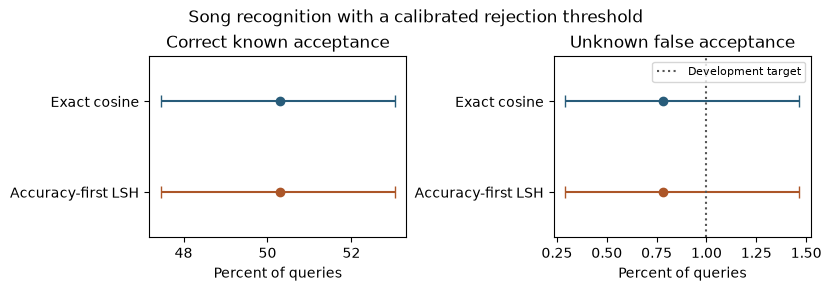

3629

In [4]:
fig, axes = plt.subplots(1,2,figsize=(8.2,2.8),layout="constrained")
for ax, metric in zip(axes, ["correct known acceptance","unknown false acceptance"],strict=True):
    data = results[(results.family == "all") & (results.metric == metric)]
    for i, row in enumerate(data.itertuples()):
        ax.errorbar(row.rate*100, i, xerr=[[100*(row.rate-row.lower)],[100*(row.upper-row.rate)]],
                    fmt="o", capsize=4, color=["#285c7a","#ac5628"][i])
    ax.set_yticks([0,1],["Exact cosine","Accuracy-first LSH"])
    ax.set_ylim(1.5,-.5)
    ax.set_xlabel("Percent of queries")
    ax.set_title(metric.capitalize())
    if metric.startswith("unknown"):
        ax.axvline(target*100,color="#555",linestyle=":",label="Development target")
        ax.legend(fontsize=8)
fig.suptitle("Song recognition with a calibrated rejection threshold")
fig.savefig(root/"reports/figures/unknown-songs.pdf",bbox_inches="tight")
plt.show()
record = {"development_false_acceptance_target":target,"seed":6821,
          "lsh":{"bits":10,"tables":64,"additional_probes":3},"evaluation":rows}
(root/"reports/unknown-songs.json").write_text(json.dumps(record,indent=2)+"\n",encoding="utf-8")